# 03 · Análise exploratória

**Objetivo:** entender os dados coletados antes de modelar. A pergunta principal: **o quanto a posição de largada já explica o resultado da corrida?** Esse vai ser o "baseline" que o modelo precisa superar.

## Setup

In [80]:
# Bibliotecas usdas no notebook 
import pandas as pd 
import glob
import matplotlib.pyplot as plt

## 1. Carregando os dados
Leio todos os CSVs salvos pelo notebook 02 e junto numa tabela só. Quando novas temporadas forem coletadas, basta rodar de novo.

In [81]:
# Lê todos os CSVs da pasta data e empilha em um único DataFrame
arquivos = glob.glob("../data/dados_*.csv")
dados = pd.concat([pd.read_csv(arq) for arq in arquivos], ignore_index=True)

print(arquivos)
dados.shape


['../data\\dados_2018.csv', '../data\\dados_2019.csv', '../data\\dados_2020.csv', '../data\\dados_2021.csv', '../data\\dados_2022.csv', '../data\\dados_2023.csv', '../data\\dados_2024.csv', '../data\\dados_2025.csv', '../data\\dados_2026.csv']


(3832, 25)

## 2. Qualidade dos dados
Antes de analisar, verifico onde há valores vazios e se eles têm explicação. Vazios esperados (como Q2 e Q3 de quem foi eliminado) são mantidos; vazios sem explicação indicam falha na coleta.

In [82]:
# Quantidade de valores vazios por coluna
dados.isna().sum()

DriverNumber             0
BroadcastName         2954
Abbreviation             0
DriverId                 0
TeamName                 0
TeamColor             2954
TeamId                   0
FirstName                0
LastName                 0
FullName                 0
HeadshotUrl           2981
CountryCode           3393
Position                 2
ClassifiedPosition       0
GridPosition             2
Time                  1245
Status                   0
Points                   0
Laps                     0
QualiPosition            9
Q1                      74
Q2                    1033
Q3                    1988
Ano                      0
GP                       0
dtype: int64

## 3. Limpeza das colunas
Removo as colunas que não ajudam a prever o resultado: as que vêm quase sempre vazias (a fonte não fornece) e as que só repetem a identificação do piloto.

In [83]:
# Reomve colunas vazias ou que só repetem algo
colunas_removidas = [
    "BroadcastName", "TeamColor", "HeadshotUrl", "CountryCode", "FirstName", "LastName", "FullName", "DriverNumber"
]

dados = dados.drop(columns=colunas_removidas)
dados.columns

Index(['Abbreviation', 'DriverId', 'TeamName', 'TeamId', 'Position',
       'ClassifiedPosition', 'GridPosition', 'Time', 'Status', 'Points',
       'Laps', 'QualiPosition', 'Q1', 'Q2', 'Q3', 'Ano', 'GP'],
      dtype='object')

### Dicionário de colunas

**Como funciona a classificação (Q1, Q2 e Q3):** no sábado, os pilotos disputam a classificação, que define a ordem de largada de domingo. Ela funciona como um mata-mata em três partes: no **Q1** todos correm e os mais lentos são eliminados; no **Q2** mais alguns são eliminados; no **Q3** os 10 mais rápidos disputam a pole position. Em cada parte, conta a melhor volta do piloto. Quem foi eliminado não tem tempo nas partes seguintes, por isso há valores vazios.

| Coluna | Significado | Quando é conhecida |
|---|---|---|
| `Abbreviation` | Sigla do piloto (ex.: NOR, VER) | Antes da corrida |
| `DriverId` | Identificador único do piloto (chave) | Antes da corrida |
| `TeamName` / `TeamId` | Equipe do piloto | Antes da corrida |
| `GridPosition` | Posição de largada | Antes da corrida |
| `QualiPosition` | Posição na classificação de sábado | Antes da corrida |
| `Q1`, `Q2`, `Q3` | Melhor volta em cada parte da classificação | Antes da corrida |
| `Position` | **Posição final na corrida (o que queremos prever)** | Depois da corrida |
| `ClassifiedPosition` | Posição oficial (`R` para quem abandonou) | Depois da corrida |
| `Status` | Como terminou (`Finished`, `Retired`...) | Depois da corrida |
| `Points` | Pontos ganhos | Depois da corrida |
| `Laps` | Voltas completadas | Depois da corrida |
| `Time` | Tempo de prova (ou diferença para o vencedor) | Depois da corrida |
| `Ano` / `GP` | Temporada e Grande Prêmio | Antes da corrida |
| `LargouPitLane` | 1 se largou do pit lane, 0 se não | Antes da corrida |
| `Equipe` | Equipe agrupada pela linhagem (nome atual) | Antes da corrida |
| `Abandonou` | 1 se não terminou (R, W ou D), 0 se terminou | **Depois da corrida** |

> Colunas conhecidas **depois** da corrida não podem ser usadas para prever o resultado: seria vazamento de dados.

## 4. Correções nos dados

### Largadas do pit lane
Nesta fonte, quem larga do pit lane aparece com `GridPosition = 0`. Como 0 sugeriria "à frente da pole", troco pelo último lugar do grid daquela corrida e guardo a informação numa coluna própria (`LargouPitLane`).

In [84]:
# Quantas largadas do pit lane (GridPosition = 0)?
dados[dados["GridPosition"] == 0][["Ano", "GP", "Abbreviation", "GridPosition", "Position"]]

,Ano,GP,Abbreviation,GridPosition,Position
199,2018,British Grand Prix,HAR,0.0,20.0
469,2019,Chinese Grand Prix,ALB,0.0,10.0
489,2019,Azerbaijan Grand Prix,RAI,0.0,10.0
495,2019,Azerbaijan Grand Prix,KUB,0.0,16.0
496,2019,Azerbaijan Grand Prix,GAS,0.0,17.0
512,2019,Spanish Grand Prix,HUL,0.0,13.0
556,2019,Canadian Grand Prix,MAG,0.0,17.0
597,2019,Austrian Grand Prix,RUS,0.0,18.0
676,2019,Belgian Grand Prix,KUB,0.0,17.0
694,2019,Italian Grand Prix,RAI,0.0,15.0


In [85]:
# Marca quem largou do pit lane e troca o 0 pelo último lugar do grid daquela corrida
dados["LargouPitLane"] = (dados["GridPosition"] == 0).astype(int)

n_carros = dados.groupby(["Ano", "GP"])["DriverId"].transform("count")
dados["GridPosition"] = dados["GridPosition"].where(dados["GridPosition"] != 0, n_carros)

(dados["GridPosition"] == 0).sum()

np.int64(0)

### Linhagem das equipes
Algumas equipes mudaram de nome ao longo dos anos (troca de dono ou patrocinador), mas são a mesma estrutura. Crio a coluna `Equipe`, que agrupa os nomes antigos sob o nome atual, para que o histórico de cada equipe não seja quebrado.

In [86]:
# Agrupa os nomes antigos de cada equipe sob o nome atual
linhagem = {
    "force_india": "aston_martin",
    "racing_point": "aston_martin",
    "toro_rosso": "rb",
    "alphatauri": "rb",
    "sauber": "audi",
    "alfa": "audi",
    "renault": "alpine",
}

dados["Equipe"] = dados["TeamId"].replace(linhagem)
dados.groupby("Equipe")["Ano"].unique()

Equipe
alpine          [2018, 2019, 2020, 2021, 2022, 2023, 2024, 202...
aston_martin    [2018, 2019, 2020, 2021, 2022, 2023, 2024, 202...
audi            [2018, 2019, 2020, 2021, 2022, 2023, 2024, 202...
cadillac                                                   [2026]
ferrari         [2018, 2019, 2020, 2021, 2022, 2023, 2024, 202...
haas            [2018, 2019, 2020, 2021, 2022, 2023, 2024, 202...
mclaren         [2018, 2019, 2020, 2021, 2022, 2023, 2024, 202...
mercedes        [2018, 2019, 2020, 2021, 2022, 2023, 2024, 202...
rb              [2018, 2019, 2020, 2021, 2022, 2023, 2024, 202...
red_bull        [2018, 2019, 2020, 2021, 2022, 2023, 2024, 202...
williams        [2018, 2019, 2020, 2021, 2022, 2023, 2024, 202...
Name: Ano, dtype: object

### Pilotos que não largaram
Dois pilotos estavam inscritos mas não largaram (Mazepin em Abu Dhabi 2021, por doença, e Mick Schumacher na Arábia Saudita 2022, após acidente na classificação). Eles não têm posição de largada nem de chegada, então são removidos.

In [87]:
# Pilotos sem posição final
nao_largaram = dados["Position"].isna()
dados[nao_largaram][["Ano", "GP", "Abbreviation", "GridPosition", "Position", "Status"]]

,Ano,GP,Abbreviation,GridPosition,Position,Status
1599,2021,Abu Dhabi Grand Prix,MAZ,NaN,NaN,Illness
1659,2022,Saudi Arabian Grand Prix,MSC,NaN,NaN,Withdrew


In [88]:
# Remove quem não largou
dados = dados[~nao_largaram]
dados.shape

(3830, 19)

### Tempos da classificação em segundos
Ao salvar em CSV, os tempos de Q1, Q2 e Q3 viraram texto (ex.: `0 days 00:01:23.348000`). Converto para segundos (ex.: `83.348`) para poder fazer contas com eles.

In [89]:
# Tipo e exempplo dos tempos de quali antes da conversão
print(dados["Q1"].dtype)
dados["Q1"].dropna().head(3)

object


0    0 days 00:01:23.348000
1    0 days 00:01:22.824000
2    0 days 00:01:23.096000
Name: Q1, dtype: object

In [90]:
# Converte Q1, Q2 e Q3 de texto para segundos
for coluna in ["Q1", "Q2", "Q3"]:
    dados[coluna] = pd.to_timedelta(dados[coluna]).dt.total_seconds()

dados[["Abbreviation", "Q1", "Q2", "Q3"]].head()

,Abbreviation,Q1,Q2,Q3
0,VET,83.348,81.944,81.838
1,HAM,82.824,82.051,81.164
2,RAI,83.096,82.507,81.828
3,RIC,83.494,82.897,82.152
4,ALO,83.597,83.692,NaN


## 5. O grid explica o resultado?
Se quem larga na frente quase sempre chega na frente, prever o resultado é fácil, e qualquer modelo precisa superar essa regra simples ("o baseline": prever que cada piloto termina onde largou).

In [91]:
# Correlação entre posição de largada e posição final
dados["GridPosition"].corr(dados["Position"], method="spearman")

np.float64(0.6244799138808873)

**Resultado:** a correlação entre largada e chegada é **0,62**. Quem larga na frente tende a chegar na frente, mas há bastante mudança durante a corrida (abandonos, punições, estratégia). O grid ajuda muito, mas não explica tudo, e é essa diferença que o modelo vai tentar capturar.

In [92]:
# Em quantos % das corridas o pole position venceu?
poles = dados[dados["GridPosition"] == 1]
venceu = poles["Position"] == 1

print("Corridas analisadas:", len(poles))
print("Vitórias da pole:", venceu.sum())
print(f"% de vitórias da pole: {venceu.mean() * 100:.1f}%")

Corridas analisadas: 190
Vitórias da pole: 102
% de vitórias da pole: 53.7%


**Resultado:** em 190 corridas, o pole position venceu 102 vezes (**53,7%**). Mesmo largando na melhor posição, o piloto vence só pouco mais da metade das vezes, o que confirma que muita coisa muda durante a corrida.

### Abandonos
Uma das causas de a corrida mudar tanto é o abandono: um piloto que larga na frente e quebra o carro termina no fim da classificação. Meço quantos pilotos abandonam e se a relação entre largada e chegada fica mais forte quando os abandonos são retirados.

In [93]:
# Marca quem não terminou: R (abandonou), W (não largou) ou D (desclassificado)
dados["Abandonou"] = dados["ClassifiedPosition"].isin(["R", "W", "D"]).astype(int)
print(f"% de abandonos: {dados['Abandonou'].mean() * 100:.1f}%")

% de abandonos: 13.6%


In [94]:
# Correlação entre largada e chegada, só com quem terminou a corrida
terminaram = dados[dados["Abandonou"] == 0]
terminaram["GridPosition"].corr(terminaram["Position"], method="spearman")

np.float64(0.7431136985440066)

**Resultado:** 13,6% dos pilotos não terminam a corrida (cerca de 2 a 3 por prova). Quando os abandonos são retirados, a correlação entre largada e chegada sobe de **0,62 para 0,74**. Ou seja, os abandonos, mesmo sendo poucos, são uma das principais fontes de imprevisibilidade. Como são difíceis de prever antes da largada, essa vai ser uma limitação do modelo; a confiabilidade recente da equipe pode ajudar a capturar parte disso.

### Chance de vitória por posição de largada

In [96]:

# % de vitórias para quem larga em cada posição (1º ao 10º)
dados["Venceu"] = (dados["Position"] == 1).astype(int)

top10 = dados[dados["GridPosition"] <= 10]
vitorias_por_grid = top10.groupby("GridPosition")["Venceu"].mean() * 100
vitorias_por_grid

GridPosition
1.0     53.684211
2.0     23.157895
3.0     10.526316
4.0      3.684211
5.0      1.052632
6.0      2.631579
7.0      0.529101
8.0      0.529101
9.0      0.526316
10.0     1.587302
Name: Venceu, dtype: float64

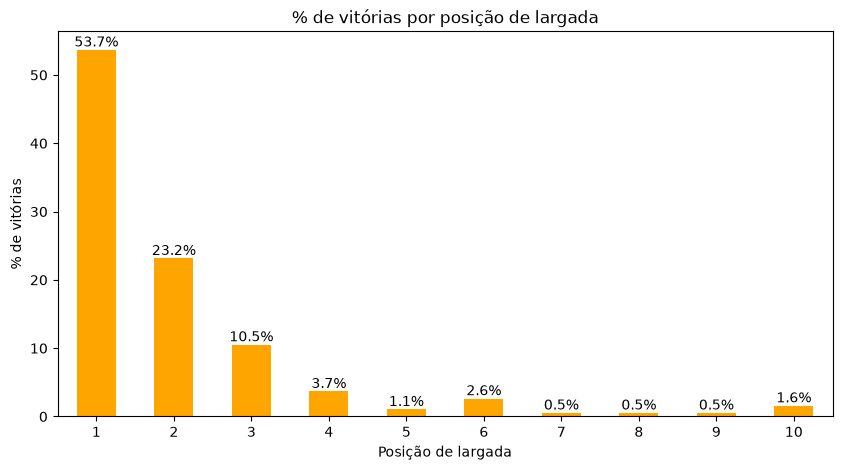

In [108]:
# Gráfico de barras com a chance de vitória por posição de largada
vitorias_por_grid.index = vitorias_por_grid.index.astype(int)

ax = vitorias_por_grid.plot(kind="bar", rot=0, color="orange", figsize=(10, 5))
ax.bar_label(ax.containers[0], fmt="%.1f%%")

plt.title("% de vitórias por posição de largada")
plt.xlabel("Posição de largada")
plt.ylabel("% de vitórias")
plt.show()

**Resultado:** a chance de vitória cai pela metade a cada posição perdida no grid: 53,7% para quem larga em 1º, 23,2% em 2º e 10,5% em 3º. Depois do 3º lugar, vencer vira raridade (menos de 4%), e os três primeiros do grid somam quase 88% das vitórias.

**Atenção:** do 5º ao 10º lugar, as vitórias são tão poucas (de 1 a 3 cada) que as diferenças entre essas barras são acaso, não um padrão. As vitórias de lá de trás costumam ser de pilotos rápidos que largaram fora de posição por punição ou classificação ruim (como Hamilton em São Paulo 2021, largando em 10º).

## 6. Conclusões

**O grid explica boa parte do resultado, mas não tudo.**

| Achado | Valor |
|---|---|
| Correlação entre largada e chegada | **0,62** |
| Vitórias de quem larga na pole | **53,7%** |
| Vitórias dos três primeiros do grid | **~88%** |
| Pilotos que não terminam a corrida | **13,6%** |
| Correlação sem os abandonos | **0,74** |

**O que isso significa para o modelo:**
- A regra simples "cada piloto termina onde largou" já acerta bastante. Esse é o **baseline** que o modelo precisa superar.
- Os **abandonos** são a principal fonte de imprevisibilidade: são poucos, mas derrubam a correlação de 0,74 para 0,62.
- Pilotos rápidos que largam fora de posição (por punição ou classificação ruim) costumam recuperar posições. Variáveis como **tempos de classificação** e **forma recente** podem ajudar o modelo a identificar esses casos.

In [ ]:
# Salva a base limpa e corrigida para ser usada no notebook 04
dados.to_csv("../data/base_limpa.csv", index=False)